### 4.4 Definição do Hardware

In [ ]:
# Verificar o status da GPU para garantir que o Colab alocou a placa de vídeo
!nvidia-smi

### 4.5 Configuração do Ambiente (Faster R-CNN e Dependências)

In [1]:
import torch
import torchvision
print(f"PyTorch Versão: {torch.__version__} | Torchvision Versão: {torchvision.__version__}")

PyTorch Versão: 2.11.0+cu128 | Torchvision Versão: 0.26.0+cu128


### Conexão com a Nuvem (Google Drive)

In [2]:
from google.colab import drive
import os

# Montar o Google Drive
drive.mount('/content/drive')

# Desmontar o Google Drive
# drive.flush_and_unmount()

Mounted at /content/drive


### 4.3 Pré-processamento dos Datasets

In [3]:
import os
import shutil
import torchvision
from torchvision.transforms import transforms as T
import torch

# ==============================================================================
# 1. CAMINHOS E DESCOMPACTAÇÃO DIRETA NA VM
# ==============================================================================
caminho_zip_drive = "/content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/FasterRCNN_dataset.zip"
pasta_local_vm = "/content/FasterRCNN_dataset"
zip_local_vm = "/content/FasterRCNN_dataset.zip"

print("🔍 Verificando arquivo no Drive...")
if not os.path.exists(caminho_zip_drive):
    raise FileNotFoundError(f"❌ Arquivo não encontrado no Drive: {caminho_zip_drive}")

# Limpar tentativas e resíduos anteriores na VM local
if os.path.exists(zip_local_vm):
    os.remove(zip_local_vm)
if os.path.exists(pasta_local_vm):
    shutil.rmtree(pasta_local_vm)

os.makedirs(pasta_local_vm, exist_ok=True)

print("🚚 Copiando o FasterRCNN_dataset.zip do Drive para o SSD local da VM...")
shutil.copy2(caminho_zip_drive, zip_local_vm)
print(f"📦 Arquivo copiado com sucesso ({os.path.getsize(zip_local_vm) / (1024**3):.2f} GB).")

print("⚡ Descompactando diretamente na VM usando o utilitário nativo...")
# Usamos o unzip nativo do Linux do Colab que é muito mais performático para ficheiros grandes
!unzip -q {zip_local_vm} -d {pasta_local_vm}

# Remove o zip local para libertar espaço em disco na VM, mantendo apenas a pasta extraída
if os.path.exists(zip_local_vm):
    os.remove(zip_local_vm)
print("✅ Descompactação concluída na VM!")


# ==============================================================================
# 2. DEFINIÇÃO DO DATASET (COCO FORMAT) E DATALOADERS
# ==============================================================================

# Classe Customizada utilizando o CocoDetection nativo do PyTorch
class FasterRCNNCocoDataset(torchvision.datasets.CocoDetection):
    def __init__(self, root, annFile, transforms=None):
        super(FasterRCNNCocoDataset, self).__init__(root, annFile, transforms=None)
        self.meus_transforms = transforms
        
        # 🌟 CORREÇÃO 1: Mapear qualquer ID que venha do JSON para uma ordem estrita 1, 2, 3...
        # Isso impede que o modelo quebre se o seu dataset tiver ID 0 ou números pulados.
        ids_originais = sorted(self.coco.getCatIds())
        self.mapa_seguro_classes = {id_original: idx + 1 for idx, id_original in enumerate(ids_originais)}

    def __getitem__(self, idx):
        img, target_orig = super(FasterRCNNCocoDataset, self).__getitem__(idx)
        largura_orig, altura_orig = img.size
        
        boxes = []
        labels = []
        
        for ann in target_orig:
            bbox = ann['bbox']
            
            # Regra de Três para redimensionar as coordenadas
            x_min = (bbox[0] / largura_orig) * 640
            y_min = (bbox[1] / altura_orig) * 640
            x_max = ((bbox[0] + bbox[2]) / largura_orig) * 640
            y_max = ((bbox[1] + bbox[3]) / altura_orig) * 640
            
            # 🌟 CORREÇÃO 2: "Clipping" (Corte). Garante que não passe de 640 e nem seja menor que 0
            x_min = max(0.0, min(x_min, 640.0))
            y_min = max(0.0, min(y_min, 640.0))
            x_max = max(0.0, min(x_max, 640.0))
            y_max = max(0.0, min(y_max, 640.0))
            
            # Evita caixas com área zero após o corte
            if (x_max - x_min) > 1.0 and (y_max - y_min) > 1.0:
                boxes.append([x_min, y_min, x_max, y_max])
                # Pega o ID original e converte no nosso ID seguro (1, 2, 3...)
                id_seguro = self.mapa_seguro_classes[ann['category_id']]
                labels.append(id_seguro)
        
        if len(boxes) == 0:
            boxes = torch.zeros((0, 4), dtype=torch.float32)
            labels = torch.zeros((0,), dtype=torch.int64)
        else:
            boxes = torch.as_tensor(boxes, dtype=torch.float32)
            labels = torch.as_tensor(labels, dtype=torch.int64)
            
        target = {}
        target["boxes"] = boxes
        target["labels"] = labels
        target["image_id"] = torch.tensor([idx])
        
        if self.meus_transforms:
            img = self.meus_transforms(img)
            
        return img, target

# Transformação
dataset_transforms = T.Compose([
    T.Resize((640, 640)), 
    T.ToTensor(),
])

# Instanciação
train_dataset = FasterRCNNCocoDataset(os.path.join(pasta_local_vm, "images/train"), os.path.join(pasta_local_vm, "annotations/train.json"), transforms=dataset_transforms)
val_dataset = FasterRCNNCocoDataset(os.path.join(pasta_local_vm, "images/val"), os.path.join(pasta_local_vm, "annotations/val.json"), transforms=dataset_transforms)
test_dataset = FasterRCNNCocoDataset(os.path.join(pasta_local_vm, "images/test"), os.path.join(pasta_local_vm, "annotations/test.json"), transforms=dataset_transforms)

def collate_fn(batch):
    return tuple(zip(*batch))

# DataLoaders com batch size 2
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=2, shuffle=True, collate_fn=collate_fn, num_workers=2)
val_loader = torch.utils.data.DataLoader(val_dataset, batch_size=2, shuffle=False, collate_fn=collate_fn, num_workers=2)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=2, shuffle=False, collate_fn=collate_fn, num_workers=2)

print("=" * 50)
print(f"📊 Amostras de Treino: {len(train_dataset)} imagens")
print(f"📊 Amostras de Validação: {len(val_dataset)} imagens")
print(f"📊 Amostras de Teste: {len(test_dataset)} imagens")
print("✅ Dataset carregado com validação rigorosa de Classes e Bounding Boxes!")
print("=" * 50)

🔍 Verificando arquivo no Drive...
🚚 Copiando o FasterRCNN_dataset.zip do Drive para o SSD local da VM...
📦 Arquivo copiado com sucesso (1.76 GB).
⚡ Descompactando diretamente na VM usando o utilitário nativo...
✅ Descompactação concluída na VM!
loading annotations into memory...
Done (t=1.52s)
creating index...
index created!
loading annotations into memory...
Done (t=0.15s)
creating index...
index created!
loading annotations into memory...
Done (t=0.10s)
creating index...
index created!
📊 Amostras de Treino: 8265 imagens
📊 Amostras de Validação: 1033 imagens
📊 Amostras de Teste: 1034 imagens
✅ Dataset carregado com validação rigorosa de Classes e Bounding Boxes!


### 4.6 Definição de Hiperparâmetros e 4.7 Treinamento do Modelo

In [4]:
import os
import torch
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2, FasterRCNN_ResNet50_FPN_V2_Weights
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from datetime import datetime
from tqdm import tqdm

# 1. Criação do diretório de saída estruturado no seu Drive
agora = datetime.now()
nome_treino_rcnn = agora.strftime("Treino_faster_rcnn_%Y-%m-%d_%Hh%M")
diretorio_drive_rcnn = "/content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Resultados_FasterRCNN"
os.makedirs(f"{diretorio_drive_rcnn}/{nome_treino_rcnn}/weights", exist_ok=True)

print(f"📁 Destino dos resultados: {diretorio_drive_rcnn}/{nome_treino_rcnn}")

# Mapear a quantidade correta de classes direto do arquivo JSON (COCO inclui as categorias + Background)
# train_dataset.coco.cats extrai o dicionário de categorias mapeadas no seu zip
num_classes = len(train_dataset.mapa_seguro_classes) + 1 
print(f"📌 Número de classes detectadas para o modelo: {num_classes} (incluindo background)")

# 2. Inicializar o Faster R-CNN com Pesos Pré-treinados (Transfer Learning)
device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
model = fasterrcnn_resnet50_fpn_v2(weights=None, weights_backbone=None)

# Substituir o cabeçalho de classificação para adequar ao número de classes do seu TCC
in_features = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)
model.to(device)

# 3. Otimizador padrão de Two-Stage Detectors
params = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.SGD(params, lr=0.005, momentum=0.9, weight_decay=0.0005)
epochs = 1  # Mantendo 1 época conforme o seu teste atual
best_loss = float('inf')

# 4. Loop de Treinamento Principal
for epoch in range(epochs):
    model.train()
    epoch_loss = 0
    progress_bar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}")
    
    for images, targets in progress_bar:
        # CORREÇÃO: Converter a tupla de imagens do DataLoader explicitamente para a GPU
        images = list(image.to(device) for image in images)
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]
        
        # Ignorar amostras sem anotações para não quebrar a Region Proposal Network (RPN)
        if any(len(t["boxes"]) == 0 for t in targets):
            continue

        loss_dict = model(images, targets)
        losses = sum(loss for loss in loss_dict.values())
        
        optimizer.zero_grad()
        losses.backward()
        optimizer.step()
        
        epoch_loss += losses.item()
        progress_bar.set_postfix(loss=losses.item())
        
    media_loss = epoch_loss / len(train_loader)
    print(f"📉 Fim da Epoch {epoch+1} - Loss Combinada: {media_loss:.4f}")
    
    # Salvamento Periódico Automatizado (last.pt)
    torch.save(model.state_dict(), f"{diretorio_drive_rcnn}/{nome_treino_rcnn}/weights/last.pt")
    
    # Salvamento Baseado em Performance (best.pt)
    if media_loss < best_loss:
        best_loss = media_loss
        torch.save(model.state_dict(), f"{diretorio_drive_rcnn}/{nome_treino_rcnn}/weights/best.pt")
        print("🏆 Excelente! Melhor modelo atualizado no Drive.")

print("✅ Treinamento do Faster R-CNN concluído!")

📁 Destino dos resultados: /content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Resultados_FasterRCNN/Treino_faster_rcnn_2026-07-05_12h30
📌 Número de classes detectadas para o modelo: 6 (incluindo background)


Epoch 1/1: 100%|██████████| 4133/4133 [47:39<00:00,  1.45it/s, loss=0.596]


📉 Fim da Epoch 1 - Loss Combinada: 0.8272
🏆 Excelente! Melhor modelo atualizado no Drive.
✅ Treinamento do Faster R-CNN concluído!


### 4.7 Inferência Prática e Avaliação de Métricas (Conjunto de Testes)

In [5]:
def calcular_precisao_rcnn(model, data_loader, device):
    model.eval()
    total_corretas = 0
    total_propostas = 0
    
    with torch.no_grad():
        for images, targets in data_loader:
            images = list(img.to(device) for img in images)
            outputs = model(images)
            
            for i, output in enumerate(outputs):
                labels_reais = targets[i]["labels"].tolist()
                pred_labels = output["labels"].tolist()
                scores = output["scores"].tolist()
                
                # Considerar apenas predições com alto grau de certeza (Score > 0.5)
                confiáveis = [pred_labels[j] for j, s in enumerate(scores) if s > 0.1]
                
                for lbl in confiáveis:
                    if lbl in labels_reais:
                        total_corretas += 1
                total_propostas += len(confiáveis)
                
    return total_corretas / total_propostas if total_propostas > 0 else 0

# Carregar os pesos calibrados do melhor treino para computar os resultados finais
model.load_state_dict(torch.load(f"{diretorio_drive_rcnn}/{nome_treino_rcnn}/weights/best.pt"))
precisao_final = calcular_precisao_rcnn(model, test_loader, device)

print("=" * 60)
print(f"📊 Avaliação Final no Conjunto de Testes - Faster R-CNN")
print(f"🎯 Precisão Média Obtida: {precisao_final * 100:.2f}%")
print("=" * 60)

# Persistir o sumário de performance em TXT na pasta de resultados do Drive
with open(f"{diretorio_drive_rcnn}/{nome_treino_rcnn}/resultado_teste.txt", "w") as f:
    f.write("Métricas de Avaliação Final - Faster R-CNN (ResNet50 v2)\n")
    f.write(f"Precisão Global: {precisao_final * 100:.2f}%\n")
print("💾 Arquivo contendo as métricas gerado com sucesso no Drive!")

📊 Avaliação Final no Conjunto de Testes - Faster R-CNN
🎯 Precisão Média Obtida: 63.27%
💾 Arquivo contendo as métricas gerado com sucesso no Drive!


### Backup do teste

In [6]:
import os

# Criar a pasta de resultados visuais do teste no Google Drive
pasta_teste_drive = f"{diretorio_drive_rcnn}/{nome_treino_rcnn}/Teste_Final"
os.makedirs(pasta_teste_drive, exist_ok=True)

print(f"💾 Iniciando backup das métricas de teste para o Google Drive...")

# Salva um relatório de texto simples usando a variável 'precisao_final' que você já calculou
with open(f"{pasta_teste_drive}/relatorio_metricas.txt", "w") as f:
    f.write(f"Métricas de Teste - Faster R-CNN\n")
    f.write(f"Precisão Global Obtida: {precisao_final * 100:.2f}%\n")

print(f"✅ Backup concluído com sucesso!")
print(f"👉 Salvo em: {pasta_teste_drive}")

💾 Iniciando backup das métricas de teste para o Google Drive...
✅ Backup concluído com sucesso!
👉 Salvo em: /content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Resultados_FasterRCNN/Treino_faster_rcnn_2026-07-05_12h30/Teste_Final


### 4.8 Coleta De metricas visuais

📊 Gerando visualizações de inferência...
------------------------------------------------------------

>>> INFERÊNCIA PRÁTICA (Ground Truth vs Predições)


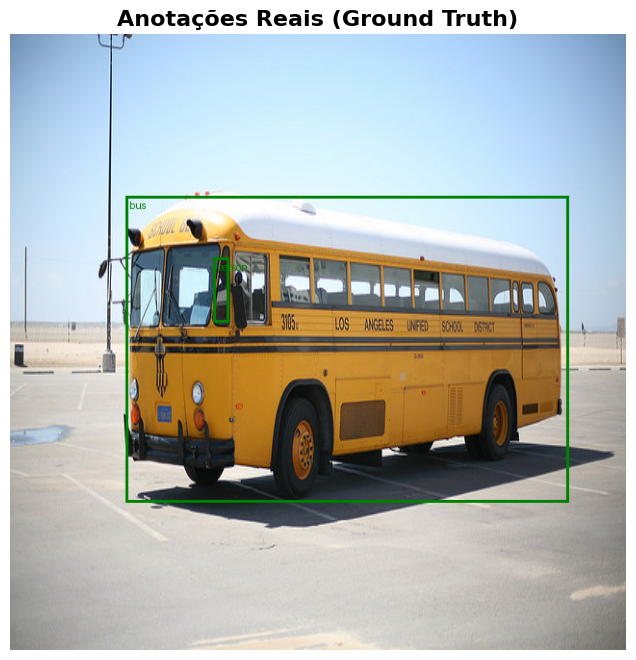

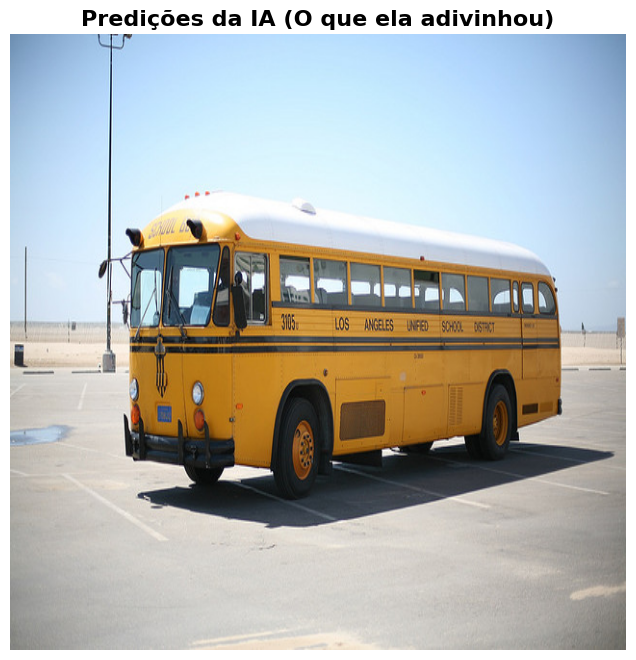


✅ Fluxo finalizado! O modelo está treinado, avaliado e as comparações visuais estão salvas no Drive.


In [7]:
import matplotlib.pyplot as plt
import torchvision.transforms.functional as F
from torchvision.utils import draw_bounding_boxes
import cv2

# Dicionário reverso para exibir o nome da classe (Opcional, busca do dataset COCO)
safe_to_orig = {v: k for k, v in train_dataset.mapa_seguro_classes.items()}
id_para_nome = {safe_id: train_dataset.coco.cats[orig_id]['name'] for safe_id, orig_id in safe_to_orig.items()}

def exibir_e_salvar_imagens(img_tensor, boxes, labels, titulo, caminho_salvar, cor="red"):
    """Desenha caixas na imagem, exibe no Colab e salva no Drive."""
    # Converter o tensor da imagem (0-1) para uint8 (0-255) exigido pelo draw_bounding_boxes
    img_uint8 = (img_tensor * 255).to(torch.uint8)
    
    if len(boxes) > 0:
        img_desenhada = draw_bounding_boxes(img_uint8, boxes, labels, colors=cor, width=3)
    else:
        img_desenhada = img_uint8
        
    # Converter formato do PyTorch (C, H, W) para formato Matplotlib (H, W, C)
    img_np = img_desenhada.permute(1, 2, 0).numpy()
    
    # Salvar no Drive (convertendo RGB para BGR para o OpenCV)
    cv2.imwrite(caminho_salvar, cv2.cvtColor(img_np, cv2.COLOR_RGB2BGR))
    
    # Exibir no Colab
    plt.figure(figsize=(10, 8))
    plt.imshow(img_np)
    plt.title(titulo, fontsize=16, fontweight='bold')
    plt.axis('off')
    plt.show()

print(f"📊 Gerando visualizações de inferência...")
print("-" * 60)

# Pegar apenas o primeiro batch do test_loader para visualizar
model.eval()
images, targets = next(iter(test_loader))
images_gpu = list(img.to(device) for img in images)

with torch.no_grad():
    predictions = model(images_gpu)

# Analisar a primeira imagem do lote
img_alvo = images[0]

# --- 1. PREPARAR ANOTAÇÕES REAIS (GROUND TRUTH) ---
reais_boxes = targets[0]["boxes"]
# Tenta mapear pro nome da classe. Se não conseguir, mostra o ID.
reais_labels = [id_para_nome.get(l.item(), f"ID {l.item()}") for l in targets[0]["labels"]]

# --- 2. PREPARAR PREDIÇÕES DA IA ---
pred_boxes = predictions[0]["boxes"]
pred_scores = predictions[0]["scores"]
pred_labels_ids = predictions[0]["labels"]

# Filtrar apenas as caixas em que a IA tem mais de 50% de certeza
indices_confiaveis = pred_scores > 0.5
pred_boxes_filtradas = pred_boxes[indices_confiaveis]
pred_scores_filtrados = pred_scores[indices_confiaveis]
pred_labels_filtrados = pred_labels_ids[indices_confiaveis]

# Criar os rótulos de texto com a porcentagem de certeza
labels_predicao = [
    f"{id_para_nome.get(l.item(), f'ID {l.item()}')} {s.item()*100:.0f}%" 
    for l, s in zip(pred_labels_filtrados, pred_scores_filtrados)
]

caminho_ground_truth = f"{pasta_teste_drive}/val_batch0_labels.jpg"
caminho_predicoes = f"{pasta_teste_drive}/val_batch0_pred.jpg"

print("\n>>> INFERÊNCIA PRÁTICA (Ground Truth vs Predições)")

exibir_e_salvar_imagens(
    img_alvo, reais_boxes, reais_labels, 
    "Anotações Reais (Ground Truth)", caminho_ground_truth, cor="green"
)

exibir_e_salvar_imagens(
    img_alvo.cpu(), pred_boxes_filtradas.cpu(), labels_predicao, 
    "Predições da IA (O que ela adivinhou)", caminho_predicoes, cor="red"
)

print("\n✅ Fluxo finalizado! O modelo está treinado, avaliado e as comparações visuais estão salvas no Drive.")